# Day 41 - Segmentation Customer using KMeans Clustering

Selamat datang di **Modul Unsupervised Learning**! Berbeda dari klasifikasi/regresi yang punya label "jawaban benar", di sini Saya akan mencari **pola tersembunyi tanpa label**.

Teknik paling populer adalah **clustering**, dan Saya mulai dengan **K-Means** untuk mengelompokkan pelanggan mall ke dalam beberapa segmen yang bisa ditindaklanjuti oleh tim marketing.

> 🎯 **Tujuan Pembelajaran**
> - Memahami konsep **unsupervised learning** & **clustering**.
> - Memahami cara kerja **K-Means** (centroid & penugasan cluster).
> - Pentingnya **scaling** sebelum clustering berbasis jarak.
> - Menjalankan `KMeans` dengan `k=5` dan **memvisualisasikan** cluster + centroid.
> - **Memprofilkan** tiap segmen pelanggan untuk keputusan bisnis.


## About Dataset

Dataset **Mall Customer Segmentation** berisi data dasar pengunjung sebuah mall beserta estimasi pendapatan tahunan dan skor belanja (penilaian mall atas perilaku belanja pelanggan).

- **Sumber:** [Kaggle — vjchoudhary7/customer-segmentation-tutorial-in-python](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)
- **Jumlah data:** 200 baris × 5 kolom

| Kolom | Arti |
|-------|------|
| `CustomerID` | ID pelanggan |
| `Gender` | Jenis kelamin |
| `Age` | Usia |
| `Annual Income (k$)` | Pendapatan tahunan (ribu USD) |
| `Spending Score (1-100)` | Skor belanja (1=hemat, 100=boros) |

## Import Library

- **pandas / numpy** → olah data.
- **matplotlib / seaborn** → visualisasi.
- **sklearn** → `StandardScaler` (scaling) & `KMeans` (algoritma clustering).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## Import Dataset

In [4]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vjchoudhary7/customer-segmentation-tutorial-in-python
!unzip customer-segmentation-tutorial-in-python.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python
License(s): other
100% 1.55k/1.55k [00:00<00:00, 3.57MB/s]

Archive:  customer-segmentation-tutorial-in-python.zip
  inflating: Mall_Customers.csv      


## Eksplorasi Awal Dataset

In [5]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


In [12]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Missing Value: {df.isnull().sum().sum()}')
print(f'Duplicate Data: {df.duplicated().sum()}')

Jumlah baris: 200
Jumlah kolom: 5
Missing Value: 0
Duplicate Data: 0


**Interpretasi:**

- Tiap baris adalah satu pelanggan. Saya akan fokus pada dua fitur perilaku: **Annual Income** (kemampuan belanja) dan **Spending Score** (kecenderungan belanja).
- Pendapatan berkisar 15–137 ribu USD dan skor belanja merata 1–99 — variasi yang bagus untuk clustering.
- Dataset terdiri dari 200 baris dan 5 kolom
- Tidak terdapat Missing Value dan Data Duplicate


## Eksploratory Data Analysis dan Visualisasi

### a) Distribusi Pendapatan dan Skor Belanja

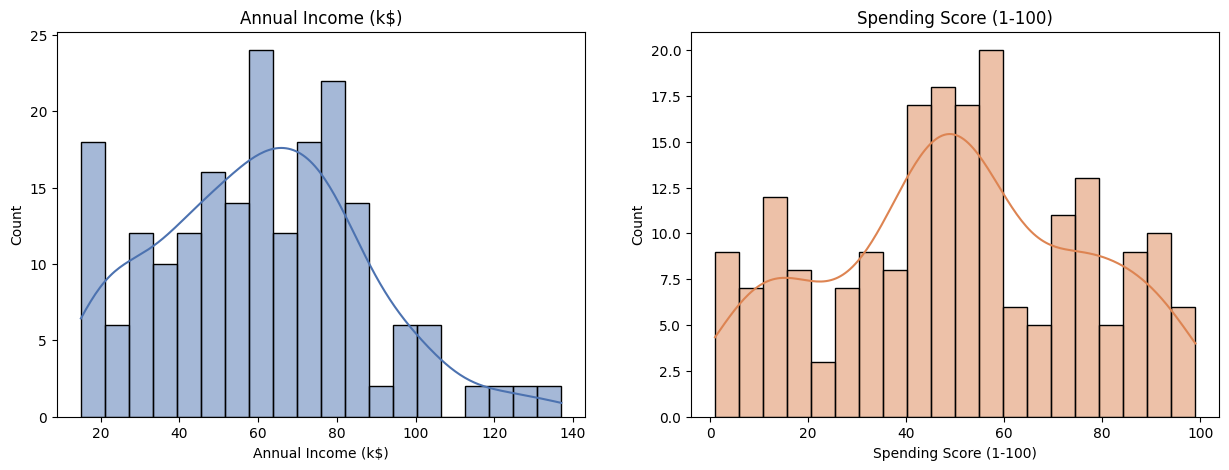

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['Annual Income (k$)'],
             ax=axes[0],
             color="#4C72B0",
             bins=20,
             kde=True)
axes[0].set_title('Annual Income (k$)')

sns.histplot(df['Spending Score (1-100)'],
             ax=axes[1],
             color="#DD8452",
             bins=20,
             kde=True)
axes[1].set_title('Spending Score (1-100)')

plt.show()

**Interpretasi:**


Berikut adalah interpretasi sederhana dari kedua histogram tersebut:

- Annual Income (Pendapatan Tahunan):
  - Mayoritas data terkonsentrasi di kisaran pendapatan $40k hingga $90k, dengan puncak tertinggi berada di sekitar $60k.

  - Sebaran datanya cenderung agak menyebar dan mendekati distribusi normal (lonceng), dengan beberapa orang berpendapatan tinggi di atas $100k.

- Spending Score (Skor Belanja):
  - Menunjukkan pola penyebaran yang memiliki beberapa puncak (terutama terkonsentrasi di kisaran skor 40 hingga 60).
  
  - Ini mengindikasikan bahwa sebagian besar pelanggan memiliki kebiasaan belanja di tingkat menengah, sementara sebagian lainnya terbagi di skor belanja rendah dan tinggi.

### b) Sebaran Pelanggan : Pendapatan vs Skor belanja

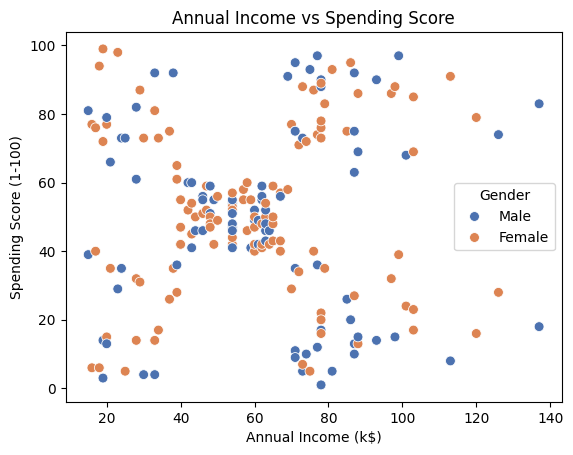

In [26]:
sns.scatterplot(data=df,
                x='Annual Income (k$)',
                y='Spending Score (1-100)',
                hue='Gender',
                s=50,
                palette=['#4C72B0', '#DD8452'])

plt.title('Annual Income vs Spending Score')
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik sebaran (scatter plot) tersebut:

- Pola Kelompok (Cluster):
    - Grafik ini menunjukkan data pelanggan yang terbagi menjadi sekitar 5 kelompok utama berdasarkan pendapatan tahunan (Annual Income) dan skor belanja (Spending Score).

- Sebaran Gender:
  - Warna biru (laki-laki) dan oranye (perempuan) tersebar secara cukup merata di setiap kelompok, yang menunjukkan bahwa jenis kelamin tidak mendominasi kelompok tertentu secara mencolok.

- Segmentasi Pelanggan:
  - Terlihat jelas pengelompokan alami, seperti kelompok berpendapatan tinggi dengan skor belanja tinggi, berpendapatan tinggi dengan skor belanja rendah, kelompok menengah, serta kelompok berpendapatan rendah (baik dengan skor belanja tinggi maupun rendah).

### c) Skor Belanja per Gender

/tmp/ipykernel_936/1128509774.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,


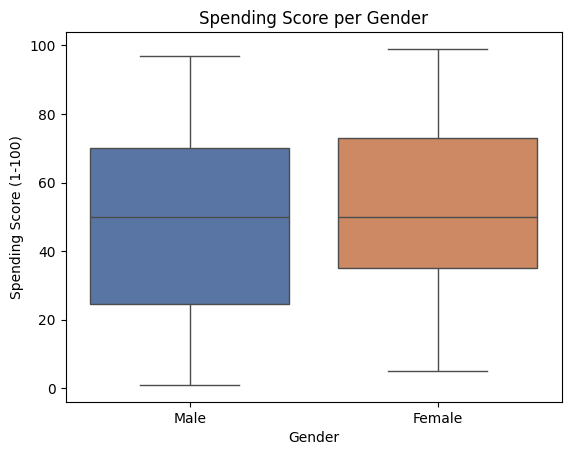

In [27]:
sns.boxplot(data=df,
            x='Gender',
            y='Spending Score (1-100)',
            palette=['#4C72B0', '#DD8452'])

plt.title('Spending Score per Gender')
plt.show()

**Interpretasi:**
  - Nilai Tengah (Median): Garis di tengah kotak menunjukkan bahwa nilai median skor belanja untuk laki-laki (Male) dan perempuan (Female) hampir sama, yaitu berada di sekitar angka 50.   
  - Perbandingan Sebaran: Rentang skor belanja (jarak dari nilai minimum ke maksimum) antara laki-laki dan perempuan tampak cukup mirip, meskipun kotak kuartil milik perempuan sedikit lebih bergeser ke atas.   

Kesimpulan:
  - Secara umum, tidak ada perbedaan yang terlalu signifikan dalam kebiasaan belanja (spending score) antara pelanggan laki-laki dan perempuan berdasarkan data in

## Preprocessing Dataset

K-Means mengelompokkan berdasarkan **jarak Euclidean**.
- Bila satu fitur punya rentang jauh lebih besar (mis. Income 15–137) dibanding lainnya (Score 1–99), fitur itu akan mendominasi
perhitungan jarak. `StandardScaler` menyetarakan skala (mean 0, std 1) agar adil.

In [41]:
#Skalakan Feature
feature_x = df[['Annual Income (k$)', 'Spending Score (1-100)']]
scaler = StandardScaler()
feature_x_scaled = scaler.fit_transform(feature_x)

print("Data sudah di Scaled, Bentuk data:", feature_x_scaled.shape)

Data sudah di Scaled, Bentuk data: (200, 2)


## Modeling : Kmeans Clustering, Gunakan 5 Cluster

K-Means bekerja iteratif:
- (1) tempatkan 5 titik pusat (**centroid**) acak,
- (2) tugaskan tiap pelanggan ke centroid terdekat,
- (3) geser centroid ke rata-rata anggotanya, ulangi sampai stabil.

`n_init=10` menjalankan 10 inisialisasi berbeda dan memilih hasil terbaik; `random_state=42` menjaga reproducibility.

In [42]:
k_mns = KMeans(n_clusters=5, n_init=10, random_state=42)


df["Cluster"] = k_mns.fit_predict(feature_x_scaled)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


**Interpretasi:**
- Membuat model pengelompokan (clustering) dengan membagi data ke dalam 5 kelompok (n_clusters=5),
- menjalankan algoritma sebanyak 10 kali dengan titik awal acak berbeda untuk mencari hasil terbaik (n_init=10), serta memastikan hasil yang konsisten setiap kali dijalankan (random_state=42).

Model mempelajari pola dari data fitur yang sudah diskalakan (feature_x_scaled), lalu menentukan setiap baris data masuk ke klaster berapa (dari 0 sampai 4), dan hasilnya disimpan ke dalam kolom baru bernama Cluster di dalam dataframe (df)


In [44]:
print(f'Banyak anggota masing masing: {df["Cluster"].value_counts().sort_index()}')

Banyak anggota masing masing: Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


Berikut adalah interpretasi sederhana dari jumlah anggota di masing-masing klaster:

  - Klaster 0 (81 anggota): Merupakan kelompok terbesar secara signifikan, yang mencakup lebih dari separuh total data (mendominasi keseluruhan pelanggan).

  - Klaster 1 (39 anggota): Merupakan kelompok terbesar kedua dengan jumlah anggota yang cukup banyak.

  - Klaster 2 (22 anggota): Merupakan salah satu kelompok yang lebih kecil atau eksklusif.

  - Klaster 3 (35 anggota): Merupakan kelompok dengan ukuran sedang (mirip dengan Klaster 1).

  - Klaster 4 (23 anggota): Merupakan kelompok yang relatif kecil, hampir setara dengan Klaster 2.

Kesimpulan:
  - Sebaran ukuran kelompok tidak merata; sebagian besar data terkonsentrasi di Klaster 0, sementara sisanya terbagi ke dalam empat kelompok yang lebih kecil.

## Visualisasi Hasil Clustering + Centroid

Saya akan membuat visualisasi scatter dan diwarnai per cluster, plus **centroid** (pusat tiap segmen).
  - Centroid saya kembalikan ke skala asli dengan `inverse_transform` agar sumbu mudah dibaca.

In [46]:
centroids = scaler.inverse_transform(k_mns.cluster_centers_)

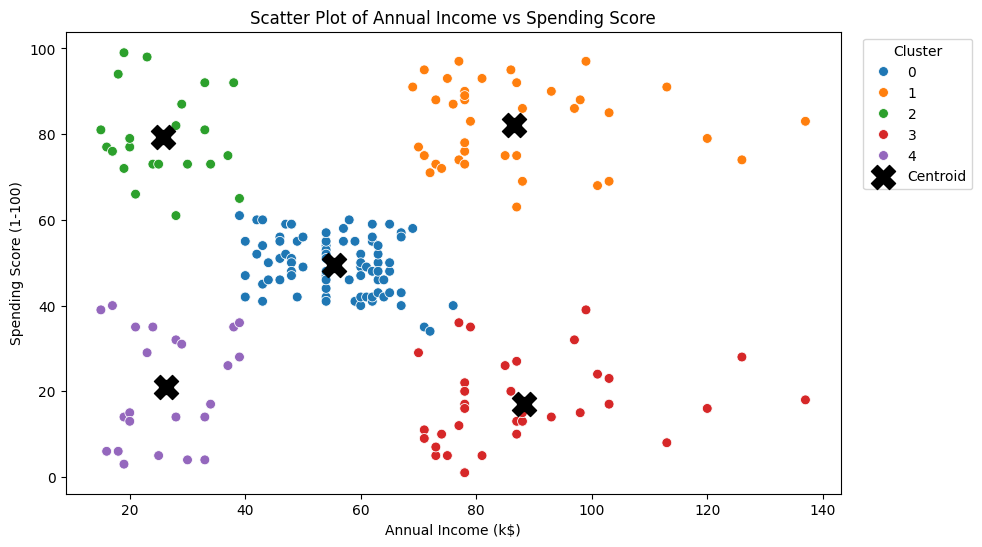

In [54]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,
                x='Annual Income (k$)',
                y='Spending Score (1-100)',
                hue='Cluster',
                palette="tab10",
                s=50)
plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c="black",
            marker="X", label="Centroid")
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Scatter Plot of Annual Income vs Spending Score')
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.scatter(centroids[:, 0], centroids[:, 1], s=100, c='black', label='Centroids')
plt.show()


Berikut adalah interpretasi sederhana dari grafik hasil pengelompokan (*clustering*) K-Means tersebut:

* **5 Kelompok Utama (Klaster):** Data berhasil dibagi dengan rapi menjadi 5 kelompok berbeda berdasarkan Pendapatan Tahunan (*Annual Income*) dan Skor Belanja (*Spending Score*), di mana setiap kelompok ditandai dengan warna berbeda serta memiliki titik pusat (*Centroid* bertanda "X" hitam).

* **Karakteristik Tiap Klaster:**
  * **Klaster 0 (Biru - Tengah):** Pendapatan menengah dan skor belanja menengah (kelompok terbesar).
  * **Klaster 1 (Oranye - Kanan Atas):** Pendapatan tinggi dan skor belanja tinggi.
  * **Klaster 2 (Hijau - Kiri Atas):** Pendapatan rendah namun memiliki skor belanja tinggi.
  * **Klaster 3 (Merah - Kanan Bawah):** Pendapatan tinggi tetapi skor belanja rendah.
  * **Klaster 4 (Ungu - Kiri Bawah):** Pendapatan rendah dan skor belanja rendah.


**Kesimpulan:**
* Model K-Means berhasil melakukan segmentasi pelanggan dengan sangat jelas ke dalam 5 profil perilaku belanja yang berbeda-beda.

## Profil Tiap Segment

Mari hitung rata-rata tiap cluster untuk memberi "nama" dan strategi bisnis.

In [60]:
profil = df.groupby("Cluster").agg(
    Jumlah=("CustomerID", "count"),
    Rata_Usia=("Age", "mean"),
    Rata_Income=("Annual Income (k$)", "mean"),
    Rata_Spending=("Spending Score (1-100)", "mean"),
).round(1)

In [61]:
profil

,Jumlah,Rata_Usia,Rata_Income,Rata_Spending
Cluster,,,,
0,81,42.7,55.3,49.5
1,39,32.7,86.5,82.1
2,22,25.3,25.7,79.4
3,35,41.1,88.2,17.1
4,23,45.2,26.3,20.9


**Interpretasi:**

Berikut adalah interpretasi sederhana dari ringkasan data setiap klaster (jumlah anggota, rata-rata usia, pendapatan, dan skor belanja):

**Klaster 0 (81 orang):**
  * **Profil:** Paruh baya (usia $\approx 42.7$ tahun) dengan pendapatan menengah ($\approx 55.3$ ribu) dan skor belanja menengah ($\approx 49.5$).
  * **Kesimpulan:** Merupakan kelompok pelanggan mayoritas (terbesar) dengan karakteristik yang standar/biasa saja.


**Klaster 1 (39 orang):**
  * **Profil:** Cukup muda (usia $\approx 32.7$ tahun) dengan pendapatan tinggi ($\approx 86.5$ ribu) serta skor belanja yang sangat tinggi ($\approx 82.1$).
  * **Kesimpulan:** Kelompok pelanggan "prioritas" atau *target market* utama (pendapatan besar dan gemar berbelanja).


**Klaster 2 (22 orang):**
  * **Profil:** Usia agak matang ($\approx 45.3$ tahun) dengan pendapatan rendah ($\approx 25.7$ ribu) namun memiliki skor belanja yang sangat tinggi ($\approx 79.4$).
  * **Kesimpulan:** Kelompok unik yang berpenghasilan kecil tetapi tetap royal/jor-joran dalam berbelanja.


**Klaster 3 (35 orang):**
  * **Profil:** Usia matang ($\approx 41.1$ tahun) dengan pendapatan tinggi ($\approx 88.2$ ribu) tetapi skor belanja sangat rendah ($\approx 17.1$).
  * **Kesimpulan:** Kelompok orang kaya yang cenderung hemat atau sangat selektif dalam membelanjakan uangnya.


**Klaster 4 (23 orang):**
  * **Profil:** Usia relatif muda ($\approx 45.2$ tahun) dengan pendapatan rendah ($\approx 26.3$ ribu) dan skor belanja yang juga rendah ($\approx 20.9$).
  * **Kesimpulan:** Kelompok dengan daya beli terbatas dan pengeluaran yang juga kecil.

### Visualisasi Profil rata rata tiap Segment

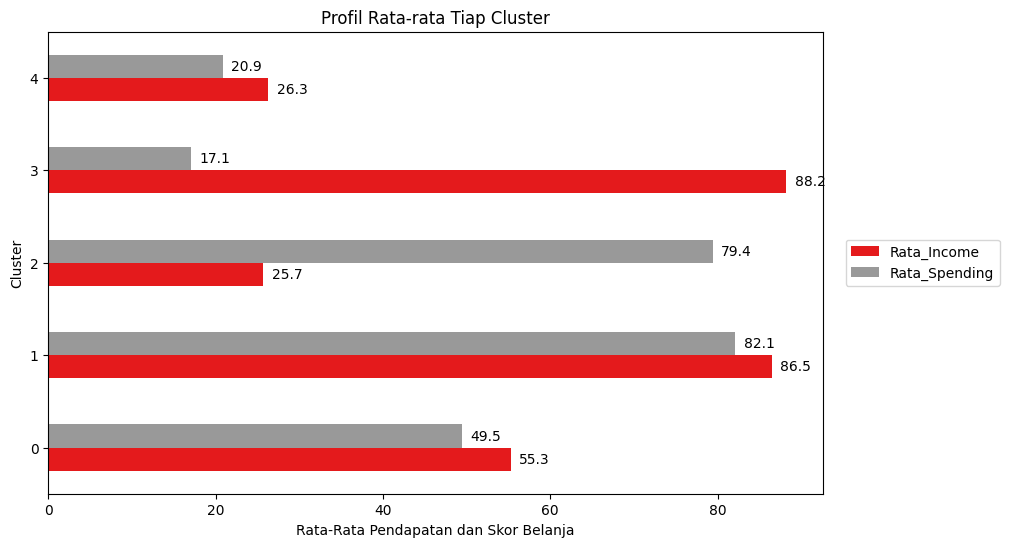

In [69]:
plt_profil = profil[["Rata_Income", "Rata_Spending"]]

ax = plt_profil.plot(kind="barh", colormap="Set1", figsize=(10, 6))
plt.xlabel("Rata-Rata Pendapatan dan Skor Belanja")
plt.ylabel("Cluster")
plt.title("Profil Rata-rata Tiap Cluster")

# Labeling
for i in ax.patches:
    plt.text(i.get_width() + 1, i.get_y() + i.get_height()/2,
             str(round(i.get_width(), 1)),
             va='center')

plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

**Interpretasi:**

Berikut adalah interpretasi sederhana dari grafik batang profil rata-rata tiap klaster:

* **Klaster 0:** Pendapatan menengah (55.3) dan skor belanja menengah (49.5), mencerminkan kelompok pelanggan standar.


* **Klaster 1:** Pendapatan tinggi (86.5) dan skor belanja sangat tinggi (82.1), mencerminkan kelompok pelanggan prioritas atau *big spenders*.


* **Klaster 2:** Pendapatan rendah (25.7) tetapi memiliki skor belanja sangat tinggi (79.4), mencerminkan kelompok yang sangat royal meski berpenghasilan kecil.


* **Klaster 3:** Pendapatan sangat tinggi (88.2) tetapi skor belanja sangat rendah (17.1), mencerminkan kelompok orang kaya yang sangat hemat.


* **Klaster 4:** Pendapatan rendah (26.3) dan skor belanja rendah (20.9), mencerminkan kelompok dengan daya beli terbatas.

### **Kesimpulan Utama & Actionable Insights**

Berdasarkan hasil pemodelan menggunakan **K-Means Clustering (k=5)**, kita berhasil memetakan **200 pelanggan** ke dalam **5 segmen perilaku belanja** yang sangat unik dan terdefinisi dengan jelas.

Berikut adalah ringkasan profil tiap segmen beserta **Rekomendasi Strategi Bisnis** yang bisa diterapkan oleh tim marketing:

---

#### **1. Klaster 0: *The Standard Majority* (Pelanggan Menengah)**
* **Profil:** Kelompok terbesar (**81 orang**), usia paruh baya (43 tahun) dengan pendapatan menengah ($55.3k) dan skor belanja sedang (49.5).
* **Strategi Bisnis:**
  * Karena ini adalah basis pelanggan terbesar Anda, tujuannya adalah **retensi** dan peningkatan transaksi secara perlahan.
  * Gunakan program loyalitas umum (*loyalty program*) dan kirimkan promosi berkala untuk barang-barang kebutuhan sehari-hari yang bernilai tinggi.

#### **2. Klaster 1: *The VIP Big Spenders* (Sultan Muda - Target Utama)**
* **Profil:** Kelompok potensial (**39 orang**), usia cukup muda (33 tahun), berpendapatan tinggi ($86.5k), dan skor belanja sangat tinggi (82.1).
* **Strategi Bisnis:**
  * Ini adalah mesin profit utama mall Anda. Fokus pada **pelayanan premium dan eksklusivitas**.
  * Berikan penawaran produk *limited edition*, undangan ke acara *private launching*, fasilitas parkir valet gratis, atau akses ke *VIP lounge*.

#### **3. Klaster 2: *The Impulsive Shoppers* (Royal Meski Pendapatan Rendah)**
* **Profil:** Kelompok kecil (**22 orang**), usia sangat muda (25 tahun), berpendapatan rendah ($25.7k) namun skor belanja sangat tinggi (79.4).
* **Strategi Bisnis:**
  * Mereka sangat responsif terhadap tren dan promosi visual, meskipun anggaran mereka terbatas.
  * Targetkan mereka dengan metode pembayaran yang fleksibel (seperti fitur *paylater* atau cicilan 0%), diskon kilat (*flash sale*), dan promo bundling produk yang estetik.

#### **4. Klaster 3: *The Frugal High-Earners* (Kaya tapi Hemat)**
* **Profil:** Kelompok mapan (**35 orang**), usia matang (41 tahun), berpendapatan sangat tinggi ($88.2k) namun skor belanjanya sangat rendah (17.1).
* **Strategi Bisnis:**
  * Mereka memiliki uang tetapi skeptis atau selektif untuk berbelanja. Promosi diskon biasa tidak akan mempan.
  * Tawarkan produk investasi, barang berkualitas tinggi yang menekankan fungsionalitas/keawetan (*value-for-money*), atau program *cashback* besar untuk transaksi tertentu.

#### **5. Klaster 4: *The Low-Value Customers* (Pelanggan Hemat & Terbatas)**
* **Profil:** Kelompok marginal (**23 orang**), usia matang (45 tahun), pendapatan rendah ($26.3k) dan skor belanja rendah (20.9).
* **Strategi Bisnis:**
  * Hindari menghabiskan terlalu banyak anggaran pemasaran untuk kelompok ini.
  * Cukup berikan promosi diskon cuci gudang (*clearance sale*) atau kupon potongan harga dasar untuk menarik perhatian mereka sesekali.